<H1>KNN<H1>
<h3>Octavio Vieyra Orozco</h3>
<p>ovieyra003@uvaq.edu.mx</p>

In [1]:
# Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar el dataset
pinguinos = pd.read_csv("/Users/octaviovieyra/Downloads/penguins_size.csv")
# Dimensiones del dataset
print("Dimensiones del dataset:", pinguinos.shape)

Dimensiones del dataset: (344, 7)


In [3]:
# Primeras filas del dataset
pinguinos.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [4]:
# Importar el algoritmo de Knn
from sklearn.neighbors import KNeighborsClassifier

In [5]:
# Estandarizamos las variables (media 0 y desviación estándar 1)
# Es importante para algoritmos sensibles a la escala como KNN
from sklearn.preprocessing import StandardScaler

In [6]:
# Importar metricas de evaluación
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [7]:
# Importar la función de división de datos
from sklearn.model_selection import train_test_split

In [8]:
# Seleccionamos las características (X) y la variable objetivo (y)
# Valores de X son las columnas de características
X = pinguinos[['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']]
# Valores de y es la columna de clasificación
y = pinguinos['species']
# Eliminar filas con valores nulos (X e y juntos, para no desalinear)
datos = pd.concat([X, y], axis=1).dropna()
X = datos.drop(columns=['species'])
y = datos['species']

# Valores X
X.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


In [9]:
# Sacar columnas de X
columns = X.columns
print("Columnas de X:", columns)

Columnas de X: Index(['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm',
       'body_mass_g'],
      dtype='object')


In [10]:
# Se divide el dataset en entrenamiento y prueba (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y) #stratify=y para mantener la proporción de clases en ambos conjuntos

print("Dimensiones del conjunto de entrenamiento:", X_train.shape)
print("Dimensiones del conjunto de prueba:", X_test.shape)

Dimensiones del conjunto de entrenamiento: (256, 4)
Dimensiones del conjunto de prueba: (86, 4)


In [11]:
# Se crea instancia de StandardScaler
scaler = StandardScaler() # Este se crea con el objetivo de estandarizar los datos, es decir, que tengan media 0 y desviación estándar 1
# Se ajusta el scaler a los datos de entrenamiento y se transforma
X_train_scaled = scaler.fit_transform(X_train) # fit_transform ajusta el scaler a los datos de entrenamiento y luego transforma esos datos (Solo con X_train)
# Transforma los datos de prueba usando los parámetros aprendidos en el entrenamiento
# Importante: aquí NO se recalcula la media ni la desviación, solo se aplica la transformación
X_test_scaled = scaler.transform(X_test) # transform transforma los datos de prueba usando el mismo scaler ajustado con X_train

In [12]:
# Definir el modelo KNN con k=4 vecinos
# Este valor de k es un punto de partida común, pero puede ajustarse según la validación cruzada o el rendimiento del modelo
k_inicial = 3
# metric='euclidean' indica que se usará la distancia euclidiana para calcular la cercanía entre puntos
knn = KNeighborsClassifier(n_neighbors=k_inicial, metric='euclidean') 
# Se entrena el modelo utilizando los datos de entrenamiento ya escalados
# X_train_scaled: variables de entrada normalizadas
# y_train: etiquetas correspondientes
knn.fit(X_train_scaled, y_train)
# Se realizan predicciones sobre los datos de prueba escalados
# El modelo asigna una clase a cada observación de X_test_scaled
y_pred = knn.predict(X_test_scaled)
# Se calcula la precisión del modelo
# accuracy_score compara las predicciones (y_pred) con los valores reales (y_test)
precision = accuracy_score(y_test, y_pred) #Es la comparación entre ambas para acertar a la precisón
print(f"Precisión con K={k_inicial}: {precision:.4f}")

Precisión con K=3: 0.9884


In [13]:
valores_k = range(1, 31) # Se define un rango de valores de k a evaluar (del 1 al 20)
precisiones = [] # Lista para almacenar las precisiones obtenidas para cada valor de k
# Se itera sobre una lista de valores posibles para k (número de vecinos)
# Esto permite evaluar diferentes configuraciones del modelo KNN y encontrar el valor óptimo de k
for k in valores_k:
    # Se crea un modelo KNN con el valor actual de k
    modelo = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    # Se entrena el modelo con los datos de entrenamiento escalados
    modelo.fit(X_train_scaled, y_train)
    # Se realizan predicciones sobre los datos de prueba escalados
    y_pred = modelo.predict(X_test_scaled)
    # Se calcula la precisión del modelo comparando predicciones vs valores reales
    # El resultado se almacena en la lista 'precisiones' para su posterior análisis
    precisiones.append(accuracy_score(y_test, y_pred))

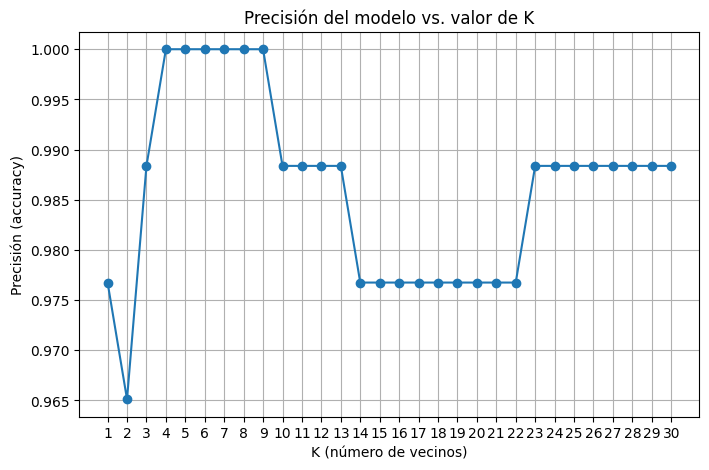

In [14]:
# Se crea una figura para graficar la precisión en función de los valores de k
plt.figure(figsize=(8, 5))
# Se grafica la relación entre los valores de K y la precisión obtenida
# marker="o" agrega puntos circulares en cada valor de K para mejor visualización
plt.plot(list(valores_k), precisiones, marker="o")
# Se define el título de la gráfica
plt.title("Precisión del modelo vs. valor de K")
# Se etiqueta el eje X (valores de K, es decir, número de vecinos)
plt.xlabel("K (número de vecinos)")
# Se etiqueta el eje Y (rendimiento del modelo medido como accuracy)
plt.ylabel("Precisión (accuracy)")
# Se aseguran marcas explícitas en el eje X para cada valor de K evaluado
plt.xticks(list(valores_k))
# Se activa la cuadrícula para facilitar la lectura de la gráfica
plt.grid(True)
# Se muestra la gráfica en pantalla
plt.show()

In [15]:
# Se identifica el índice del valor máximo dentro de la lista de precisiones
# np.argmax devuelve la posición donde la precisión es más alta
indice_mejor = np.argmax(precisiones)
# Se selecciona el valor de K correspondiente a ese índice
# Es decir, el K que obtuvo la mejor precisión en el conjunto de prueba
mejor_k = list(valores_k)[indice_mejor]
print(f"Mejor valor de K encontrado: {mejor_k} (precisión = {max(precisiones):.4f})")

Mejor valor de K encontrado: 4 (precisión = 1.0000)


In [16]:
# Se crea el modelo final de K-Nearest Neighbors utilizando el mejor valor de K encontrado
# n_neighbors=mejor_k asegura que el modelo use la configuración con mejor rendimiento
# metric="euclidean" indica que la distancia entre puntos se calcula con distancia euclidiana
modelo_final = KNeighborsClassifier(n_neighbors=mejor_k, metric="euclidean")
# Se entrena el modelo final con los datos de entrenamiento escalados
# X_train_scaled: variables de entrada normalizadas
# y_train: etiquetas correspondientes a cada observación
modelo_final.fit(X_train_scaled, y_train)
# Se realizan predicciones finales sobre el conjunto de prueba escalado
# Este es el modelo ya optimizado con el mejor valor de K
y_pred_final = modelo_final.predict(X_test_scaled)
print(f"Precisión final del modelo (K={mejor_k}): {accuracy_score(y_test,y_pred_final):.4f}")

Precisión final del modelo (K=4): 1.0000


In [17]:
# Se imprime un reporte completo de evaluación del modelo de clasificación
# classification_report incluye métricas como:
# - precision (exactitud por clase)
# - recall (sensibilidad por clase)
# - f1-score (balance entre precision y recall)
# - support (número de ejemplos reales por clase)
print(classification_report(y_test, y_pred_final))

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        38
   Chinstrap       1.00      1.00      1.00        17
      Gentoo       1.00      1.00      1.00        31

    accuracy                           1.00        86
   macro avg       1.00      1.00      1.00        86
weighted avg       1.00      1.00      1.00        86



In [18]:
pinguino_nuevo = pd.DataFrame({
    'culmen_length_mm': [45.0],
    'culmen_depth_mm': [15.0],
    'flipper_length_mm': [210],
    'body_mass_g': [4800],
})
# Se estandarizan los nuevos datos (fruta_nueva) usando el mismo scaler entrenado
# Es importante usar transform (no fit_transform) para mantener la misma escala del entrenamiento
pinguino_nuevo_escalado = scaler.transform(pinguino_nuevo)
# Se realiza la predicción de la clase para la nueva observación
# El modelo devuelve la clase más probable según los vecinos cercanos
prediccion = modelo_final.predict(pinguino_nuevo_escalado)
# Se obtienen las probabilidades asociadas a cada clase
# predict_proba muestra qué tan probable es que la muestra pertenezca a cada categoría
probabilidades = modelo_final.predict_proba(pinguino_nuevo_escalado)
print("Clase predicha:", prediccion[0])
print("Probabilidades por clase:")
for clase, prob in zip(modelo_final.classes_, probabilidades[0]):
    print(f"  {clase}: {prob:.2%}")

Clase predicha: Gentoo
Probabilidades por clase:
  Adelie: 0.00%
  Chinstrap: 0.00%
  Gentoo: 100.00%


In [19]:
# Comparar precisión en train vs test para descartar overfitting
y_train_pred = modelo_final.predict(X_train_scaled)
precision_train = accuracy_score(y_train, y_train_pred)
precision_test = accuracy_score(y_test, y_pred_final)

print(f"Precisión en entrenamiento: {precision_train:.4f}")
print(f"Precisión en prueba: {precision_test:.4f}")

Precisión en entrenamiento: 0.9922
Precisión en prueba: 1.0000
